# Transformer. Seminar 5. Классификация текстов

Сначала термины с лекции: что такое NLU и как устроена метка на весь текст. Классификацию отдельных токенов не разбираем.

Потом дообучаем `rubert-tiny2` на отзывах о фильмах.


## 1. NLU

NLU (Natural Language Understanding) — из текста достают структуру: метку, сущность или связь. Это задачи энкодера. Перевод, суммаризация и генерация ответа — уже декодер, их на этом семинаре нет.

Три постановки:

- весь текст получает одну или несколько меток: спам, тональность, тема, токсичность, намерение в диалоге
- каждый токен получает метку: именованные сущности, части речи. Это отдельная тема, сегодня её не берём
- связь между кусками: кто такой «он», кто что написал

Одну и ту же прикладную задачу можно поставить по-разному. От этого зависят и качество, и стоимость.


### Вопрос. Почему не LLM на всё

Почему не решать любую задачу NLP большой языковой моделью?

1. LLM не умеют NLU: ни сущности, ни тональность.
2. LLM всегда отвечают точно.
3. LLM не надо настраивать, формат ответа и так стабильный.
4. Для метки, сущности и разбора часто хватает энкодера: он быстрее и не генерирует текст.


### Ответ

Четвёртое. LLM такие задачи умеют, но для готовой метки это дорого, ответ может разъехаться, и формат часто приходится дожимать промптом или дообучением. Энкодер сразу выдаёт класс.


## 2. Одна метка или несколько

Многоклассовая классификация: ровно один класс из многих. Бренд по запросу, хотя брендов тысячи. Тема новости: спорт или политика.

Мультилейбл: несколько классов сразу. Жанры фильма — и комедия, и боевик.

Сегодня многоклассовая задача на двух классах: отзыв положительный или отрицательный. Это бинарная классификация.


## 3. Вектор и голова

Идея та же, что у логистической регрессии и fastText. Сначала вектор всего текста, сверху линейный слой.

Токенизатор за один вызов режет текст, ставит `[CLS]` и `[SEP]`, подставляет номера из словаря.

На выходе BERT — матрица `батч × длина × размер`. Для метки всего текста берём вектор `[CLS]`. Линейный слой превращает его в логиты, активация — в вероятности, дальше loss.

![Классификация по CLS](figures/nlu/cls_head.png)

На рисунке линейный слой нарисован отдельно, поверх DistilBERT. У нас тот же слой сидит внутри `BertForSequenceClassification`.

Одна метка на текст: softmax. Вероятности от 0 до 1, сумма равна 1. Loss — кросс-энтропия.

Несколько меток сразу: sigmoid на каждый логит и binary cross entropy. Классы друг друга не вытесняют.


### Вопрос. Какая активация, если метка одна

1. Sigmoid: она оценивает каждый класс отдельно и всегда стоит в классификации.
2. Softmax: выходы становятся распределением, сумма 1, рядом кросс-энтропия.
3. ReLU: обнуляет отрицательные числа, так модель устойчивее.
4. Tanh: диапазон от −1 до 1, это удобно читать как вероятность.


### Ответ

Второе, softmax. Sigmoid — для мультилейбла. ReLU и tanh не дают вероятности по классам.


## 4. Что учить

Голова — линейный слой над энкодером. Можно заморозить BERT и учить только её. Можно учить всю сеть. Так экономят время и память: случайная голова дешёвая, а 29 миллионов весов энкодера двигать необязательно.

В лонгриде этот цикл спрятан в `Trainer`. Ниже те же три строки видны явно: loss, `backward`, `step`.


## 5. Метрики

Loss нужен оптимизатору. Качество смотрят отдельно.

Accuracy — доля верных среди всех ответов. Если минусов 99 из 100, модель «всегда минус» получает 0.99 и ничего не находит.

Precision — среди отзывов, названных положительными, какая доля правда положительные. Это цена ложной тревоги.

Recall — среди положительных отзывов какую долю модель нашла. Это цена пропуска.

F1 собирает оба числа. Низкий precision или низкий recall тянет её вниз:

`F1 = 2 · precision · recall / (precision + recall)`


### Вопрос. Классы неравны

Положительных отзывов мало. Какую метрику смотреть?

1. Accuracy.
2. F1.
3. Только recall.
4. Только precision.


### Ответ

Второе, F1. Accuracy завышает частый класс. Recall без precision не показывает, сколько раз модель подняла ложную тревогу. Precision без recall не показывает, сколько плюсов она пропустила.


## 6. Что делаем руками

Тональность: плюс или минус у отзыва на фильм. В прямой похвале хватает ключевых слов. Сарказм и отрицание уже нет, сегодня берём прямые отзывы.

Рядом другие постановки, их не учим: токсичность часто мультилейбл и с сильным дисбалансом, тема новости — много классов, намерение в чат-боте — короткая фраза, спам иногда закрывается правилом без сети.

Дальше тот же план в коде. Модель `rubert-tiny2`, голова новая.


## 7. Зависимости


In [1]:
import csv
import os
from pathlib import Path

os.environ.setdefault("HF_HOME", str(Path(".hf_cache").resolve()))
os.environ.setdefault("MPLCONFIGDIR", str(Path(".mplconfig").resolve()))

import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, BertForSequenceClassification

plt.rcParams["figure.dpi"] = 120

torch.manual_seed(0)
torch.set_num_threads(min(4, os.cpu_count() or 1))

name = "models/rubert-tiny2"
max_len = 256
tokenizer = AutoTokenizer.from_pretrained(name, local_files_only=True)
names = ["отрицательный", "положительный"]


/Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/fedorkurushin/Documents/ChatGPT/seminars_mephi/transformers/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 8. Отзывы на фильмы

Тональность. Датасет Кинопоиска `ai-forever/kinopoisk-sentiment-classification`: классы Bad, Neutral, Good.

Рецензии длинные, в файл легли первые 320 символов. Около тысячи строк, плюс и минус поровну. `1` — Good, `0` — Bad. В начале часто уже стоит оценка, вроде «фильм гениален» или «игра ужасна». Сарказм сюда не попал.

Первые 800 строк идут в обучение. Остальные в оптимизатор не попадают, по ним смотрим точность.


In [2]:
from datasets import load_dataset

ds = load_dataset("ai-forever/kinopoisk-sentiment-classification")

In [3]:
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 10500
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 1500
    })
})

In [4]:
import pandas as pd

In [5]:
ds['train'].to_pandas()[['text', 'label']].to_csv('data/reviews_train.csv', index=False)
ds['test'].to_pandas()[['text', 'label']].to_csv('data/reviews_test.csv', index=False)

In [6]:
train = ds['train'].to_pandas()[['text', 'label']].to_dict(orient='records')
test = ds['test'].to_pandas()[['text', 'label']].to_dict(orient='records')

In [7]:
# rows = list(csv.DictReader(open("data/reviews.csv")))
# for row in rows:
#     row["label"] = int(row["label"])

# train, test = rows[:800], rows[800:]
# print("обучение", len(train), "проверка", len(test))
# print("плюсы в обучении", sum(row["label"] for row in train))
# print()

# for title, label in (("плюс", 1), ("минус", 0)):
#     print(title)
#     shown = 0
#     for row in train:
#         if row["label"] != label:
#             continue
#         print(" ", row["text"])
#         shown += 1
#         if shown == 2:
#             break
#     print()


## 9. Голова

Код к схеме из раздела 3. `BertForSequenceClassification` — тот же BERT и линейный слой. На вход слоя идёт pooler: вектор `[CLS]` после tanh. На прошлом семинаре этот вектор назывался Pooling. Из 312 чисел получаются 2 логита.

`CrossEntropyLoss` сам делает log_softmax. Отдельно softmax не пишем.

Предупреждение при загрузке ожидаемое. В файле весов головы MLM и NSP, для этой задачи они не нужны. `classifier.weight` в файле нет, слой создаётся заново.


In [8]:
# model = BertForSequenceClassification.from_pretrained(name, num_labels=3, local_files_only=True)

model = BertForSequenceClassification.from_pretrained(name, num_labels=3, local_files_only=True)
for p in model.bert.parameters():
    p.requires_grad = False
# fit(model)

def nparams(module):
    return sum(p.numel() for p in module.parameters())

print(model.classifier)
print("голова:", nparams(model.classifier))
print("bert:  ", nparams(model.bert))


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at models/rubert-tiny2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Linear(in_features=312, out_features=3, bias=True)
голова: 939
bert:   29193768


In [9]:
import re

def process_text(text):
    text = text.lower()
    text = re.sub(r'[^а-я0-9\s]', '', text)
    return text

# train = [process_text(row['text']) for row in train]
# test = [process_text(row['text']) for row in test]

In [10]:
# out = tokenizer([process_text(text) for text in list(ds['train']['text']) ], padding=True, truncation=True, return_tensors="pt")

In [11]:
# torch.sum(out['input_ids'] != 0) / out['input_ids'].shape[0]

In [12]:
# torch.sum(out['input_ids'] != 0) / out['input_ids'].shape[0]

## 10. Батч

Токенизатор отдаёт номера токенов и маску. Короткий отзыв дополняется `[PAD]` до длины батча, на этих позициях маска 0.

В обучении длина 96: начало рецензии из файла туда влезает. Ниже отдельно режем один отзыв до 24 токенов, чтобы увидеть обрезку.


In [13]:
def encode(part):
    enc = tokenizer(
        [row["text"] for row in part],
        padding=True,
        truncation=True,
        max_length=max_len,
        return_tensors="pt",
    )
    labels = torch.tensor([row["label"] for row in part])
    return enc["input_ids"], enc["attention_mask"], labels

sample = [train[0], train[1]]
ids, mask, _ = encode(sample)
for text, row_ids, row_mask in zip([row["text"] for row in sample], ids, mask):
    tokens = tokenizer.convert_ids_to_tokens(row_ids.tolist())
    cut = tokens.index("[PAD]") if "[PAD]" in tokens else len(tokens)
    print(text)
    print(" ", " ".join(tokens[:cut]))
    if cut < len(tokens):
        print("  паддинг", len(tokens) - cut, "маска", int(row_mask[cut]))
    print()

Если честно, меня не очень впечатлила новость, о том, что Гай Ричи собирается снять фильм, о Шерлоке Холмсе. Подумал — да это же будет: Карты, деньги, два ствола — у Холмса и у Ватсона. Но затем по мере появления трейлеров, и большей информации поменял своё отношение.
«Шерлок Холмс» — последняя картина, на которую я планировал пойти в этом году. Жутко боялся, что она меня разочарует т. к. перед этим были расстроившие «Безумный спецназ», «Так себе каникулы» и немного 2012. Но Холмс полностью оправдал доверия.
Сюжет
В ленте динамичный, а главное интересный и захватывающий сюжет, что в последнее время не так уж и часто. Новый Холмс не поход классический образ представленный в картинах Игоря Масленникова, но это не портит его образ. Он больше подобен на Тони Старку из «Железного человека» или Грегори Хаусу из сериала «Доктор Хаус». Как и они, он весьма харизматичен, слегка безумен, но гениален в своём любимом деле.
На первый взгляд сюжет портит сверхъестественное восстание из могилы лорда 

In [14]:
train_ids, train_mask, train_y = encode(train)
test_ids, test_mask, test_y = encode(test)
print("обучение", tuple(train_ids.shape), "метки", tuple(train_y.shape))
print("проверка", tuple(test_ids.shape))

long = max(train, key=lambda row: len(row["text"]))
full = tokenizer(long["text"])["input_ids"]
short = tokenizer(long["text"], truncation=True, max_length=24)["input_ids"]
print("без обрезки", len(full), "токенов, если резать до 24 —", len(short))
print(tokenizer.decode(short))

Token indices sequence length is longer than the specified maximum sequence length for this model (4548 > 2048). Running this sequence through the model will result in indexing errors


обучение (10500, 256) метки (10500,)
проверка (1500, 256)
без обрезки 4548 токенов, если резать до 24 — 24
[CLS] I. Глаз ведьмы : - Вперёд, быстрей, не отставай, [UNK] отрывисто шипел [SEP]


## 12. Один шаг

Восемь отзывов. Модель считает логиты, loss сравнивает их с метками, `backward` пишет градиенты, `step` двигает веса. Цикл обучения — повтор этих строк. В лонгриде то же самое спрятано внутри `Trainer`.


In [15]:
opt = torch.optim.AdamW(model.parameters(), lr=1e-5)
model.train()
batch = slice(0, 8)
opt.zero_grad()
loss = model(
    input_ids=train_ids[batch],
    attention_mask=train_mask[batch],
    labels=train_y[batch],
).loss
loss.backward()
opt.step()
print("loss", round(loss.item(), 3))


loss 1.123


## 13. Три эпохи

Эпоха — один проход по 800 отзывам, батчами по 16. После каждой эпохи печатаем средний loss на обучении и долю верных на проверке.

Шаг `2e-4`. Для большого BERT обычно берут `2e-5`. Здесь сеть маленькая, шаг больше.

Один шаг из прошлого раздела уже сдвинул веса. Дальше идём с этого места.


In [16]:
# wandb
from livelossplot import PlotLosses

In [17]:
model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(83828, 312, padding_idx=0)
      (position_embeddings): Embedding(2048, 312)
      (token_type_embeddings): Embedding(2, 312)
      (LayerNorm): LayerNorm((312,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-2): 3 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=312, out_features=312, bias=True)
              (key): Linear(in_features=312, out_features=312, bias=True)
              (value): Linear(in_features=312, out_features=312, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=312, out_features=312, bias=True)
              (LayerNorm): LayerNorm((312,), eps=1e-

In [18]:
def accuracy(model, ids, mask, y):
    model.eval()
    with torch.no_grad():
        out = model(input_ids=ids, attention_mask=mask)
        pred = torch.argmax(out.logits, dim=1)
        return (pred == y).float().mean().item()

In [19]:
train_ids.shape

torch.Size([10500, 256])

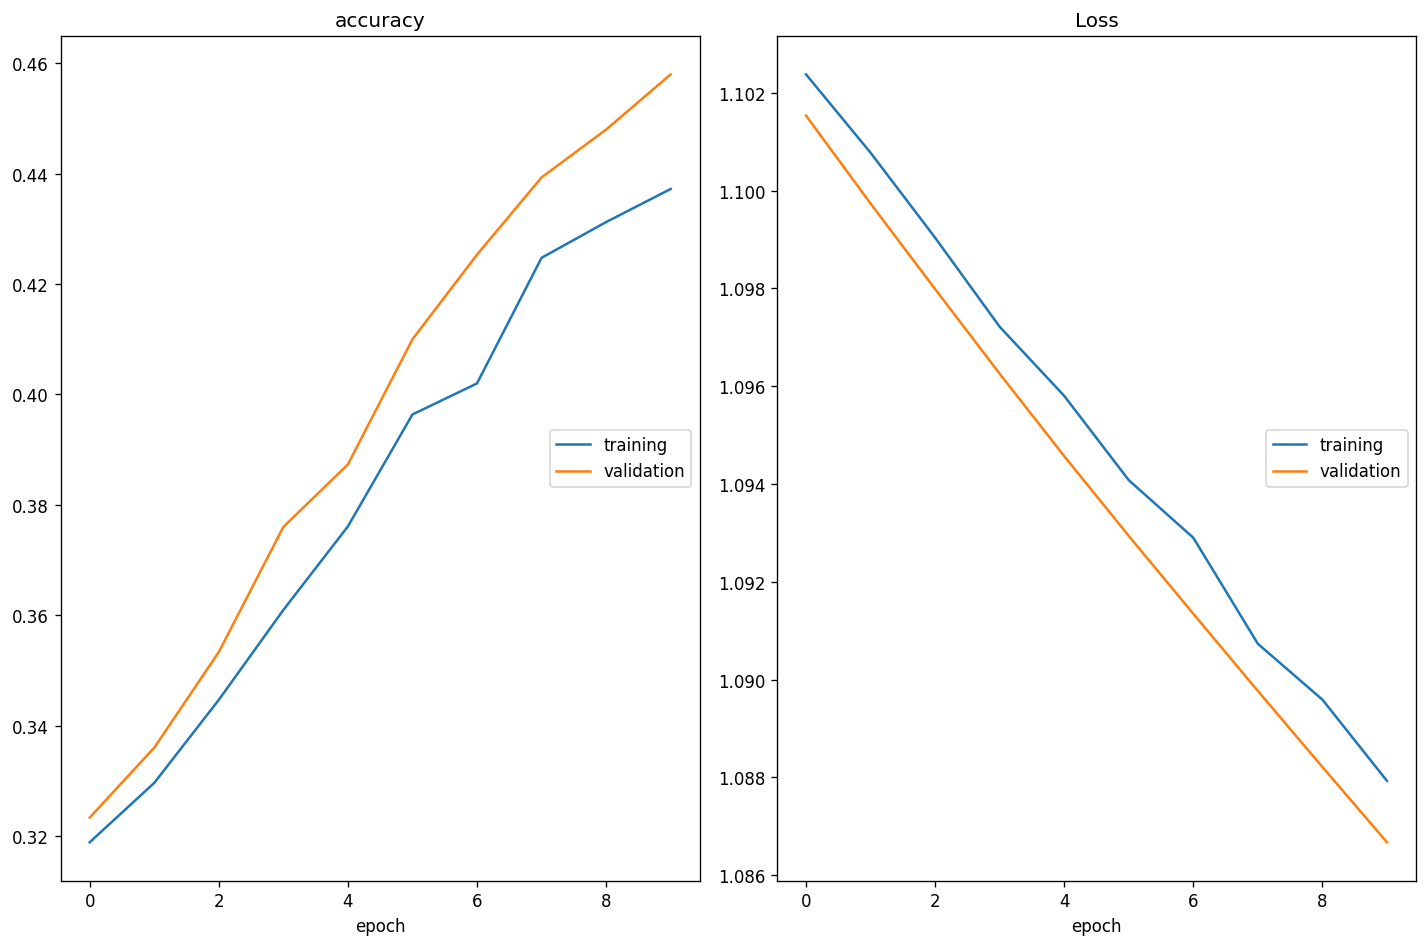

accuracy
	training         	 (min:    0.319, max:    0.437, cur:    0.437)
	validation       	 (min:    0.323, max:    0.458, cur:    0.458)
Loss
	training         	 (min:    1.088, max:    1.102, cur:    1.088)
	validation       	 (min:    1.087, max:    1.102, cur:    1.087)


In [20]:
def fit(model, epochs=3, batch_size=16):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=1e-5)
    print("учим параметров", sum(p.numel() for p in params))
    plot = PlotLosses()
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(train_y))
        total, correct, n = 0.0, 0, 0
        for i in range(0, len(train_y), batch_size):
            b = perm[i:i + batch_size]
            opt.zero_grad()
            out = model(
                input_ids=train_ids[b],
                attention_mask=train_mask[b],
                labels=train_y[b],
            )
            out.loss.backward()
            opt.step()
            k = len(b)
            total += out.loss.item() * k
            correct += (out.logits.argmax(1) == train_y[b]).sum().item()
            n += k

        model.eval()
        test_total, test_correct, m = 0.0, 0, 0
        with torch.no_grad():
            for i in range(0, len(test_y), batch_size):
                b = slice(i, i + batch_size)
                out = model(
                    input_ids=test_ids[b],
                    attention_mask=test_mask[b],
                    labels=test_y[b],
                )
                k = len(test_y[b])
                test_total += out.loss.item() * k
                test_correct += (out.logits.argmax(1) == test_y[b]).sum().item()
                m += k

        logs = {
            "loss": total / n,
            "val_loss": test_total / m,
            "accuracy": correct / n,
            "val_accuracy": test_correct / m,
        }
        plot.update(logs)
        plot.send()

fit(model, epochs=10, batch_size=64)

In [21]:
model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(83828, 312, padding_idx=0)
      (position_embeddings): Embedding(2048, 312)
      (token_type_embeddings): Embedding(2, 312)
      (LayerNorm): LayerNorm((312,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-2): 3 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=312, out_features=312, bias=True)
              (key): Linear(in_features=312, out_features=312, bias=True)
              (value): Linear(in_features=312, out_features=312, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=312, out_features=312, bias=True)
              (LayerNorm): LayerNorm((312,), eps=1e-

## 15. Precision и recall

Считаем определения из раздела 5. Плюс — положительный класс. Порог 0.5: плюс, если `p(плюс)` не меньше половины.

F1 — одно число из precision и recall. Классы здесь почти поровну, поэтому accuracy, precision, recall и F1 близки. На дисбалансе так не будет.

Кривая — те же вероятности, порог едет от высокого к низкому. Красная точка — порог 0.5. Вероятности прижаты к 0 и 1, поэтому точка сидит в правом верхнем углу: двигать порог почти нечего.


In [ ]:
# precision recall curve

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    model.eval()
    with torch.no_grad():
        out = model(input_ids=test_ids, attention_mask=test_mask)
        scores = out.logits[:, 1]
        pred = scores >= threshold
        # precision = 


SyntaxError: invalid syntax (2259791898.py, line 9)